# Text Mining Basics: Sephora Moisturizer Reviews

This notebook applies text mining techniques to the cleaned dataset built in `1_Build_Final_Dataset.ipynb` and explored in `2_Data_Exploration.ipynb`.

**1. Keyword and Frequency Analysis**
- Most common terms in low-rated reviews
- Terms that distinguish low-rated from high-rated reviews
- Terms that distinguish oily-skin from dry-skin reviews

**2. Baseline Sentiment Analysis**
- Lexicon-based sentiment scores compared against star ratings

**3. Topic Modeling**
- Not used, since it overlaps with Claude's complaint labeling that will be used in Phase 3 (explained below)

**4. Plan for Phase 3**
- Analysis path, planned use of Claude with sample prompts, and concerns

## Setup and Data Load

In [2]:
%pip install -q scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
# To handle changes to src/utils.py without restarting the kernel
%load_ext autoreload
%autoreload 2           

# Imports
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from src.utils import load_data

In [4]:
# Data load
df = load_data()

# Combine title and text so short complaint titles ("Broke me out!") are included
df["full_text"] = df["review_title"].fillna("") + ". " + df["review_text"]
print(f"Loaded {len(df):,} reviews")

Loaded 184,664 reviews


## 1. Keyword and Frequency Analysis

**Approach:** Terms are measured as the share of reviews that contain them rather than raw counts, so one long review repeating a word doesn't skew results. Both single words and two-word phrases are included, since phrases like "broke out" or "not moisturizing" carry more meaning than single words. 

In the oily vs. dry comparison, "oily" and "dry" have the largest gaps, partly because reviewers use them to describe their own skin ("I have dry skin"). Removing them was considered but not done, because the same words also describe what a product did ("this left my skin dry," "I felt oily all day"), and no simple rule reliably separates the two uses. Removing the words, or phrases like "dry skin," would also discard real complaints. They are kept, with the understanding that their gaps mix self-description and complaints, so the analysis focuses on the other terms in the comparison.

Standard English stopwords are removed, except negations ("not," "no," "never"), which change a phrase's meaning in reviews. Words that appear in nearly every review regardless of opinion ("skin," "moisturizer," "product") are also removed.

To keep processing fast, each comparison group is capped at a random sample of 30,000 reviews. At that size, term shares are estimated precisely.

In [5]:
# Setting up the customized stop word list. We want to keep negations, and add some domain-specific words that are not informative for our analysis.
negations = {"not", "no", "nor", "never", "cannot"}
domain_words = {"skin", "face", "moisturizer", "moisturizers", "product", "products",
                "cream", "creams", "use", "used", "using", "just", "really"}
cust_stopwords = list((ENGLISH_STOP_WORDS - negations) | domain_words)

max_per_group = 30000

# Function to randomly sample reviews if there are more than 30,000 reviews in a group. This is to avoid having one group dominate the analysis.
def cap_sample(texts, n=max_per_group, seed=42):
    """If there are more than n reviews, randomly pick n of them (each review stays complete)."""
    return texts.sample(n=min(n, len(texts)), random_state=seed)

# Function to compute the percent of reviews containing each term (words and two-word phrases).
def term_shares(texts, ngram_range=(1, 2), min_df=30):
    """Percent of reviews containing each term (words and two-word phrases)."""
    vec = CountVectorizer(stop_words=cust_stopwords, ngram_range=ngram_range,
                          min_df=min_df, binary=True)
    X = vec.fit_transform(texts)
    shares = np.asarray(X.mean(axis=0)).ravel() * 100
    return pd.Series(shares, index=vec.get_feature_names_out()).sort_values(ascending=False)

# Function to compare the percent of reviews containing each term in two groups, and the gap in percentage points.
def compare_terms(texts_a, texts_b, label_a, label_b, ngram_range=(1, 2), min_df=30):
    """Percent of reviews containing each term in two groups, and the gap in percentage points."""
    vec = CountVectorizer(stop_words=cust_stopwords, ngram_range=ngram_range,
                          min_df=min_df, binary=True)
    X = vec.fit_transform(pd.concat([texts_a, texts_b]))
    n_a = len(texts_a)
    share_a = np.asarray(X[:n_a].mean(axis=0)).ravel() * 100
    share_b = np.asarray(X[n_a:].mean(axis=0)).ravel() * 100
    out = pd.DataFrame({label_a: share_a, label_b: share_b}, index=vec.get_feature_names_out())
    out["gap_pts"] = out[label_a] - out[label_b]
    return out.round(2)

# Function to plot a horizontal bar chart of terms, largest at the top.
def plot_terms(series, title, xlabel="% of reviews containing term"):
    """Horizontal bar chart of terms, largest at the top."""
    ax = series.sort_values().plot(kind="barh", color="#4C72B0", figsize=(7, 5))
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

In [6]:
# Define the rating groups for analysis
low = df[df["rating"] <= 2]
high = df[df["rating"] >= 4]
print(f"Low-rated (1-2 stars): {len(low):,} reviews ({len(low)/len(df):.1%})")
print(f"High-rated (4-5 stars): {len(high):,} reviews ({len(high)/len(df):.1%})")

Low-rated (1-2 stars): 17,143 reviews (9.3%)
High-rated (4-5 stars): 153,384 reviews (83.1%)


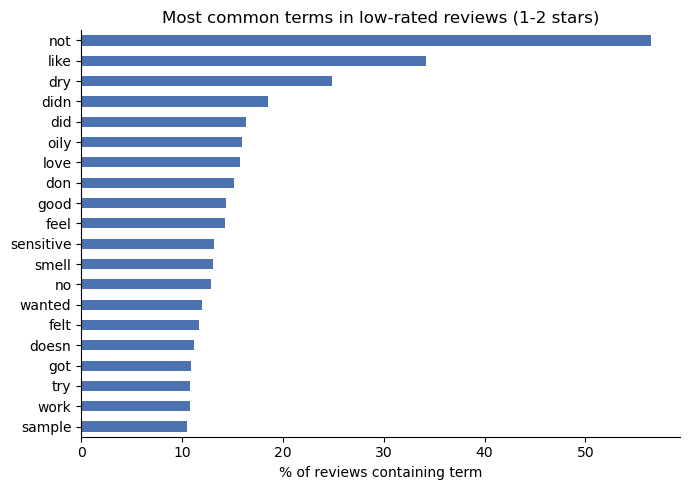

In [7]:
# Find the most common terms in low-rated reviews (1-2 stars)
low_terms = term_shares(cap_sample(low["full_text"]))
plot_terms(low_terms.head(20), "Most common terms in low-rated reviews (1-2 stars)")

More common in low-rated reviews:


,low_rated_pct,high_rated_pct,gap_pts
not,56.56,28.82,27.74
didn,18.57,6.37,12.20
wanted,11.96,1.15,10.80
did,16.39,6.80,9.59
broke,9.07,0.36,8.71
like,34.19,25.80,8.39
work,10.79,2.91,7.88
disappointed,7.88,0.57,7.31
bad,8.99,1.92,7.07
wanted love,6.29,0.05,6.24


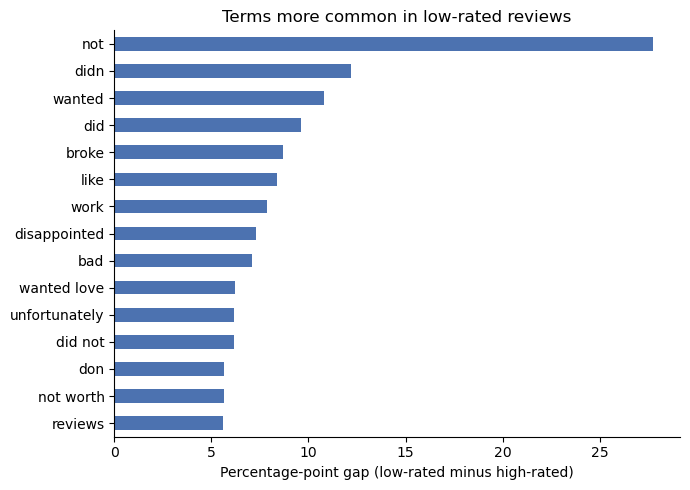

More common in high-rated reviews:


,low_rated_pct,high_rated_pct,gap_pts
love,15.74,40.25,-24.51
great,9.93,25.52,-15.59
amazing,2.88,15.96,-13.08
soft,2.02,14.09,-12.07
hydrated,2.60,13.82,-11.22
smooth,2.22,12.07,-9.85
light,3.86,13.53,-9.67
feels,10.16,18.79,-8.64
perfect,1.29,9.62,-8.32
definitely,6.38,14.63,-8.25


In [8]:
# Find the terms that are more common in low-rated reviews than high-rated reviews, and vice versa
rating_gap = compare_terms(cap_sample(low["full_text"]), cap_sample(high["full_text"]),
                           "low_rated_pct", "high_rated_pct")

print("More common in low-rated reviews:")
display(rating_gap.sort_values("gap_pts", ascending=False).head(15))
plot_terms(rating_gap["gap_pts"].nlargest(15),
           "Terms more common in low-rated reviews",
           "Percentage-point gap (low-rated minus high-rated)")

print("More common in high-rated reviews:")
display(rating_gap.sort_values("gap_pts").head(15))

1-3 star reviews: oily 3,685 | dry 6,844


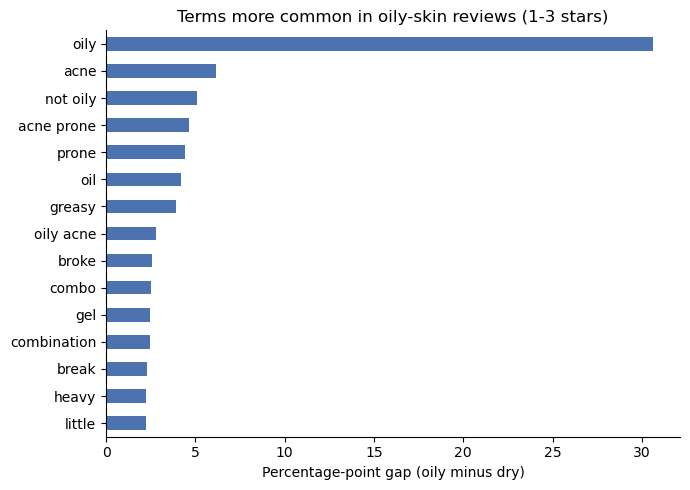

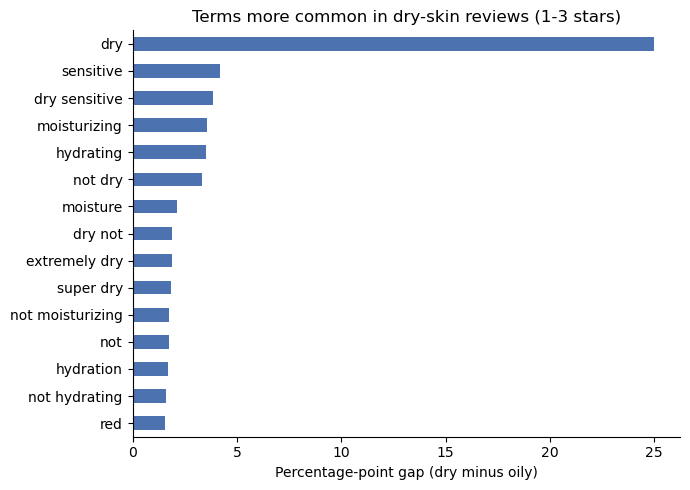

In [9]:
# Find the terms that are more common in oily-skin reviews than dry-skin reviews, and vice versa, among low-rated reviews

# Reviews rated 1-3 stars, where complaints are concentrated (3-star reviews are often mixed)
unhappy = df[df["rating"] <= 3]
oily = unhappy.loc[unhappy["skin_type"] == "oily", "full_text"]
dry = unhappy.loc[unhappy["skin_type"] == "dry", "full_text"]
print(f"1-3 star reviews: oily {len(oily):,} | dry {len(dry):,}")

skin_gap = compare_terms(oily, dry, "oily_pct", "dry_pct")

plot_terms(skin_gap["gap_pts"].nlargest(15),
           "Terms more common in oily-skin reviews (1-3 stars)",
           "Percentage-point gap (oily minus dry)")
plot_terms((-skin_gap["gap_pts"]).nlargest(15),
           "Terms more common in dry-skin reviews (1-3 stars)",
           "Percentage-point gap (dry minus oily)")

**Observations**

- Only 9.3% of reviews (17,143) are rated 1–2 stars, while 83.1% are rated 4–5 stars. Complaints are therefore a small share of the text, which is why the comparisons above measure the share of reviews containing a term within each group rather than raw counts.
- The most frequent terms in 1–2 star reviews are general sentiment and negation words: "not" appears in 57% of them and "like" in 34%. Fragments such as "didn," "don," and "doesn" come from the tokenizer splitting contractions ("didn't") and also act as negations. Skin-related words do appear: "dry" (25%), "oily" (16%), "sensitive" (13%), and "smell" (13%). Even so, frequency alone mostly surfaces how reviewers express disappointment rather than what went wrong.
- The clearest complaint signals are "broke" (as in "broke me out"), which appears in 9.1% of low-rated reviews vs. 0.4% of high-rated ones, and "not worth" (5.7% vs. 0.1%). Disappointment language is also distinctive: "wanted love" (from "wanted to love it," 6.3% vs. 0.05%), "unfortunately," and "disappointed." High-rated reviews describe how the product feels: "soft," "hydrated," "smooth," and "light" each appear in 12–14% of high-rated reviews vs. 2–4% of low-rated ones.
- Among 1–3 star reviews (3,685 oily, 6,844 dry), "oily" and "dry" show by far the largest gaps (about 30 and 25 percentage points). As noted in the approach, these mix reviewers describing their own skin with complaints about results, so they aren't interpreted on their own. The remaining terms are more informative. Oily-skin reviews more often mention acne and breakouts ("acne," "acne prone," "broke," "break"), greasiness ("greasy," "oil," "heavy"), and gel textures. Dry-skin reviews more often mention a lack of moisture ("not moisturizing," "not hydrating," "extremely dry") and sensitivity ("sensitive," "dry sensitive," "red"). This matches the expected pattern: heavy textures disappoint oily skin, and products that don't moisturize enough disappoint dry skin.
- "Not oily" (oily-skin list) and "not dry" (dry-skin list) could be praise ("it's not oily at all," "my skin is not dry anymore") or reviewers describing their own skin ("I'm not dry, more combination"), and counts can't tell which. Because stopwords are removed before phrases are formed, some phrases also join words that weren't next to each other in the review ("wanted to love it" becomes "wanted love"). Single words and phrases also can't show how many distinct complaints a review contains. These limits are why Phase 3 uses Claude to label complaints in context rather than relying on keyword counts.
- **Implications for Phase 3:** The terms above suggest a starting set of complaint categories: greasy/heavy, breakouts, not moisturizing enough, irritation/redness, fragrance/smell, not worth the price, and no visible results. Claude's suggestions on a sample of reviews will refine this list.

---